In [2]:
import os, json, random
from collections import defaultdict
import cv2
import torch
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import albumentations as A
root = '/kaggle/input/datasets/ammarnassanalhajali/pklot-dataset'

def load_coco(split):
    folder = os.path.join(root, split)
    with open(os.path.join(folder, '_annotations.coco.json')) as f:
        coco = json.load(f)
    img_to_anns = defaultdict(list)
    for a in coco['annotations']:
        img_to_anns[a['image_id']].append(a)
    images = [im for im in coco['images'] if len(img_to_anns[im['id']]) > 0]
    return folder, images, img_to_anns

In [3]:
train_transform = A.Compose([
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=5, p=0.3, border_mode=cv2.BORDER_CONSTANT),
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))
class ParkingDataset(Dataset):
    def __init__(self, folder, images, img_to_ans, transforms=None):
        self.folder = folder
        self.images = images
        self.img_to_ans = img_to_ans
        self.transforms = transforms

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        img = cv2.imread(os.path.join(self.folder, info['file_name']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        boxes, labels = [], []
        for a in self.img_to_ans[info['id']]:
            x, y, w, h = a['bbox']
            if w > 0 and h > 0:
                boxes.append([x, y, x + w, y + h]) 
                labels.append(a['category_id'])

        if self.transforms is not None:
            augmented = self.transforms(image=img, bboxes=boxes, labels=labels)
            img = augmented['image']
            boxes = augmented['bboxes']
            labels = augmented['labels']

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
            labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            'boxes': boxes,
            'labels': labels,
            'image_id': torch.tensor([info['id']]),
        }
        
        img = torch.as_tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        return img, target

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [4]:
train_ds = ParkingDataset(*load_coco('train'), transforms=train_transform)
val_ds   = ParkingDataset(*load_coco('valid'))
test_ds  = ParkingDataset(*load_coco('test'))

random.seed(42)
N_TRAIN, N_VAL = 500, 100  
train_sub = Subset(train_ds, random.sample(range(len(train_ds)), N_TRAIN))
val_sub   = Subset(val_ds,   random.sample(range(len(val_ds)), N_VAL))

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(train_sub, batch_size=4, shuffle=True, collate_fn=collate_fn, num_workers=2)
val_loader   = DataLoader(val_sub, batch_size=4, shuffle=False, collate_fn=collate_fn, num_workers=2)


img, tgt = train_ds[0]
print(img.shape, tgt['boxes'].shape, tgt['labels'].unique())

torch.Size([3, 640, 640]) torch.Size([40, 4]) tensor([1, 2])


In [6]:
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=weights)

num_classes = 3 
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

for name, param in model.named_parameters():
    if "backbone.body.layer1" in name or "backbone.body.layer2" in name:
        param.requires_grad = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
print(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 231MB/s]  


cuda


In [ ]:
num_epochs = 6
best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for images, targets in train_loader:
        images = [i.to(device) for i in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        train_loss += losses.item()

   
    val_loss = 0
    with torch.no_grad():
        for images, targets in val_loader:
            images = [i.to(device) for i in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            val_loss += sum(model(images, targets).values()).item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)
    print(f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train:.4f} | Val: {avg_val:.4f}")

    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), 'best_parking_model.pth')
        print("--> تم حفظ أفضل نموذج")

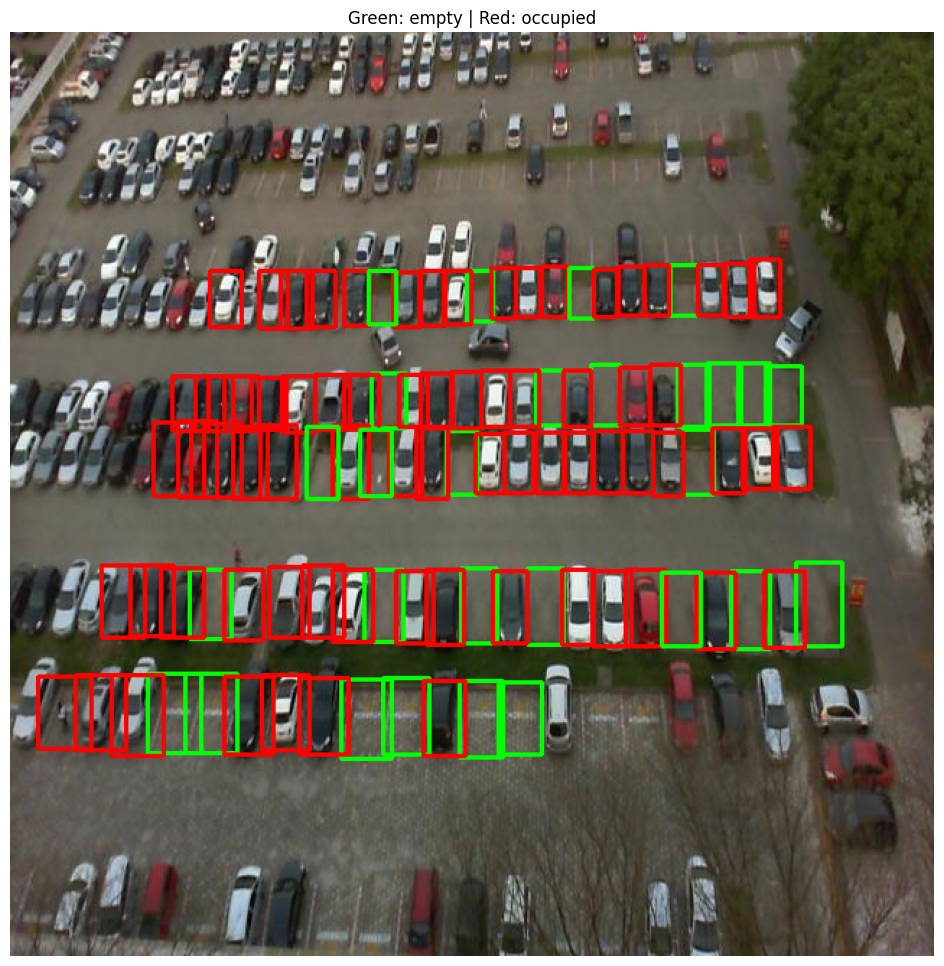

In [27]:
model.load_state_dict(torch.load('/kaggle/input/notebooks/fedasadeer/notebook7567021e1c/best_parking_model.pth'))
model.eval()
THR = 0.7
model.roi_heads.score_thresh = THR
model.roi_heads.nms_thresh = 0.3
img_t, _ = test_ds[11]
with torch.no_grad():
    pred = model([img_t.to(device)])[0]

show = (img_t.permute(1, 2, 0).numpy() * 255).astype('uint8').copy()
for box, label, score in zip(pred['boxes'], pred['labels'], pred['scores']):
    if score.item() > THR:
        x1, y1, x2, y2 = map(int, box.tolist())
        color = (0, 255, 0) if label.item() == 1 else (255, 0, 0)  # RGB
        cv2.rectangle(show, (x1, y1), (x2, y2), color, 2)

plt.figure(figsize=(12, 12))
plt.imshow(show)
plt.axis('off')
plt.title("Green: empty | Red: occupied")
plt.show()

frames: 849


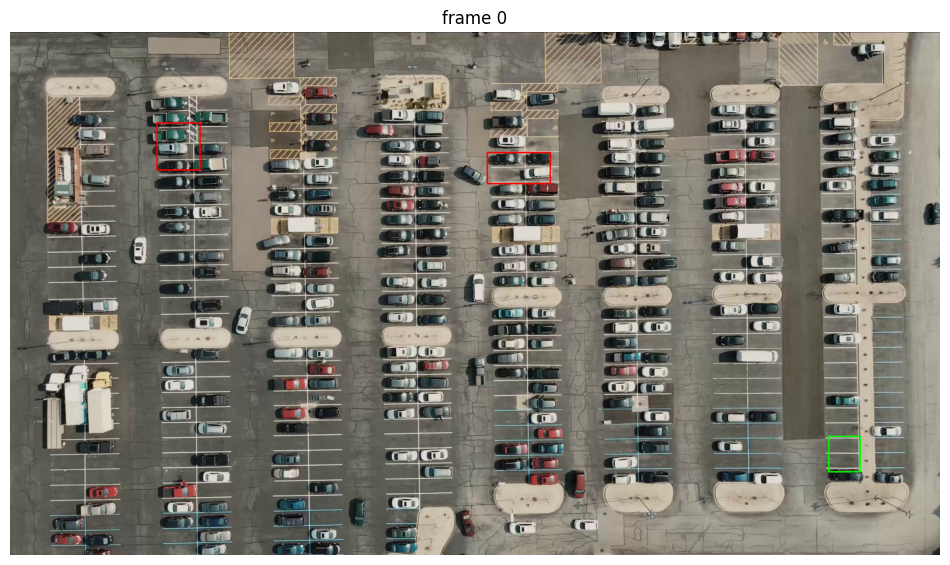

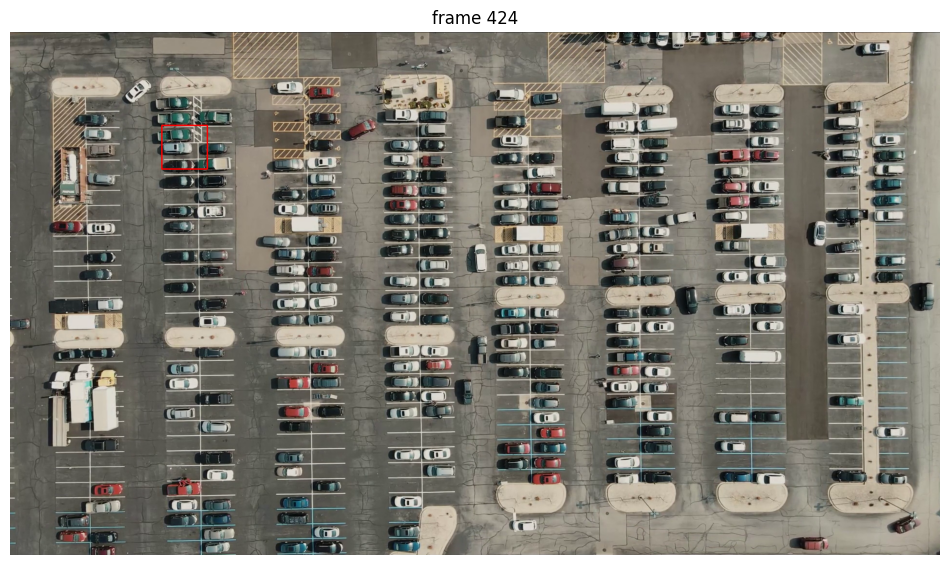

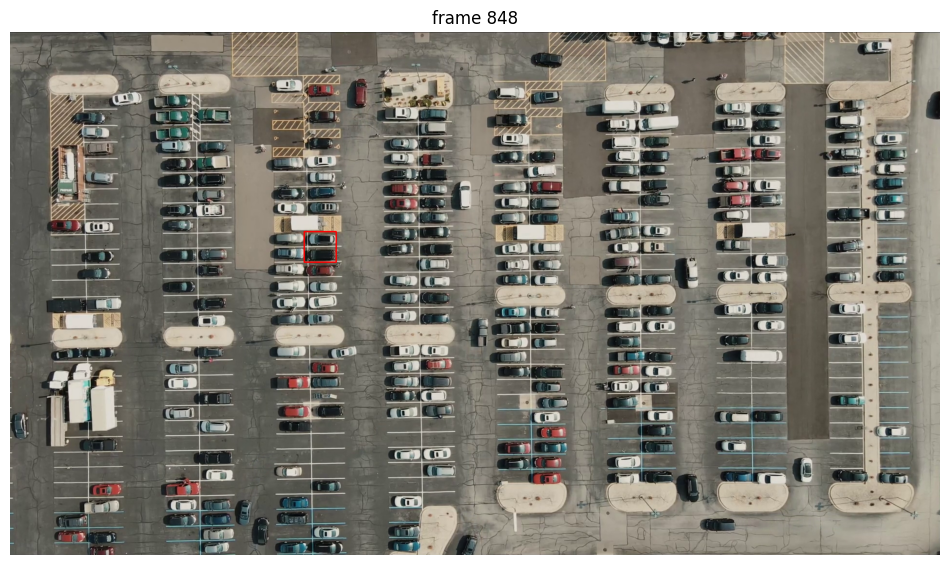

In [26]:


video = '/kaggle/input/datasets/iasadpanwhar/parking-lot-detection-counter/parking/parking_1920_1080.mp4'
THR = 0.2

cap = cv2.VideoCapture(video)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("frames:", total)

model.eval()
for n in [0, total // 2, total - 1]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, n)
    ok, frame = cap.read()
    if not ok:
        continue
    img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    img_t = torch.as_tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
    with torch.no_grad():
        pred = model([img_t.to(device)])[0]

    show = img.copy()
    for box, label, score in zip(pred['boxes'], pred['labels'], pred['scores']):
        if score.item() > THR:
            x1, y1, x2, y2 = map(int, box.tolist())
            color = (0, 255, 0) if label.item() == 1 else (255, 0, 0)
            cv2.rectangle(show, (x1, y1), (x2, y2), color, 2)

    plt.figure(figsize=(12, 7))
    plt.imshow(show)
    plt.axis('off')
    plt.title(f"frame {n}")
    plt.show()
cap.release()